# Illicit transaction classification under temporal drift: data, splits and baseline

This notebook covers steps 2 to 5 of the project workflow for the idea in
[`research/idea_illicit_transaction_drift.md`](../../research/idea_illicit_transaction_drift.md):

1. **Data.** Download the Elliptic dataset, validate it against the published description.
2. **Preprocessing and split.** Exploratory analysis aimed at preprocessing, chronological train / dev / test split, leakage checks.
3. **Baseline.** Task, metrics, protocol, and a fixed baseline, including a reproduction of the published numbers.
4. **Method fit.** What kind of drift happens at the dark market shutdown, whether it can be detected, and whether retraining helps.

The literature review is in [`research/literature/literature_review_illicit_drift.md`](../../research/literature/literature_review_illicit_drift.md)
and the conclusions are in [`research/illicit_drift_writeup.md`](../../research/illicit_drift_writeup.md).

Reusable code lives in `src/scripts/elliptic.py`, with tests in `tests/test_elliptic.py`.
The first run downloads about 150 MB; the whole notebook takes about 6 minutes.

In [1]:
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors

sys.path.append("../scripts")
import elliptic as el

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)

TRAIN_END, DEV_END, SHUTDOWN = el.TRAIN_END, el.DEV_END, el.SHUTDOWN_STEP   # 26, 34, 43
FEATURES = el.feature_columns()               # 165 features, the time step itself excluded
LOCAL = el.feature_columns("local")

# Chart style: one fixed colour per series, thin lines, quiet grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 90, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
    "lines.linewidth": 1.4, "legend.frameon": False, "font.size": 9.5,
})

def mark_periods(ax, labels=True):
    # Dashed lines at the split boundaries and at the dark market shutdown.
    for x in (TRAIN_END + 0.5, DEV_END + 0.5):
        ax.axvline(x, color=MUTED, linewidth=0.8, linestyle=(0, (4, 3)))
    ax.axvline(SHUTDOWN - 0.5, color=ORANGE, linewidth=1.0, linestyle=(0, (1, 2)))
    if labels:
        top = ax.get_ylim()[1]
        for text, x in [("train", 1), ("dev", TRAIN_END + 1), ("test", DEV_END + 1), ("after shutdown", SHUTDOWN)]:
            ax.annotate(text, (x, top), xytext=(2, -11), textcoords="offset points", color=MUTED, fontsize=8.5)

## 1. Data

**The Elliptic dataset** (Weber et al., 2019) is a graph of Bitcoin transactions released by the analytics
company Elliptic. Each node is a transaction, each edge a flow of bitcoin from one transaction to the next.
A transaction is labeled licit or illicit according to the entity that made it (exchanges, miners and
services against scams, ransomware, dark markets and the like), where that entity is known.

**Source.** The original release is on [Kaggle](https://www.kaggle.com/datasets/ellipticco/elliptic-data-set)
and needs an account. The same three files are served without one by the PyTorch Geometric project, which is
what `el.load_elliptic()` downloads into `data/elliptic/` (ignored by git).

In [2]:
nodes, edges = el.load_elliptic()
known = el.labeled(nodes)
step_of = nodes.set_index("tx_id")["time_step"]

checks = pd.DataFrame({
    "this download": {
        "transactions (nodes)": len(nodes), "payment flows (edges)": len(edges), "time steps": nodes["time_step"].nunique(),
        "features (with the time step)": len(FEATURES) + 1, "illicit": int((nodes["label"] == 1).sum()),
        "licit": int((nodes["label"] == 0).sum()), "unknown": int((nodes["label"] == -1).sum()),
    },
    "published (Weber et al., 2019)": {
        "transactions (nodes)": 203769, "payment flows (edges)": 234355, "time steps": 49,
        "features (with the time step)": 166, "illicit": 4545, "licit": 42019, "unknown": 203769 - 4545 - 42019,
    },
})
checks["match"] = checks.iloc[:, 0] == checks.iloc[:, 1]
display(checks)

integrity = pd.Series({
    "duplicate transaction ids": int(nodes["tx_id"].duplicated().sum()),
    "missing values": int(nodes.isna().sum().sum()),
    "edges with an end that is not a node": int((~edges["src"].isin(nodes["tx_id"])).sum() + (~edges["dst"].isin(nodes["tx_id"])).sum()),
    "edges between different time steps": int((edges["src"].map(step_of) != edges["dst"].map(step_of)).sum()),
    "self loops": int((edges["src"] == edges["dst"]).sum()),
    "duplicate edges": int(edges.duplicated().sum()),
    "transactions with identical features": int(nodes[FEATURES].duplicated().sum()),
}, name="count")
integrity.to_frame()

,this download,"published (Weber et al., 2019)",match
transactions (nodes),203769,203769,True
payment flows (edges),234355,234355,True
time steps,49,49,True
features (with the time step),166,166,True
illicit,4545,4545,True
licit,42019,42019,True
unknown,157205,157205,True


,count
duplicate transaction ids,0
missing values,0
edges with an end that is not a node,0
edges between different time steps,0
self loops,0
duplicate edges,0
transactions with identical features,34


**The download matches the published description exactly**, and the data is internally consistent: no
missing values, no dangling or duplicate edges, and no edge connects two different time steps. Each time
step is its own separate graph.

## 2. Descriptive statistics

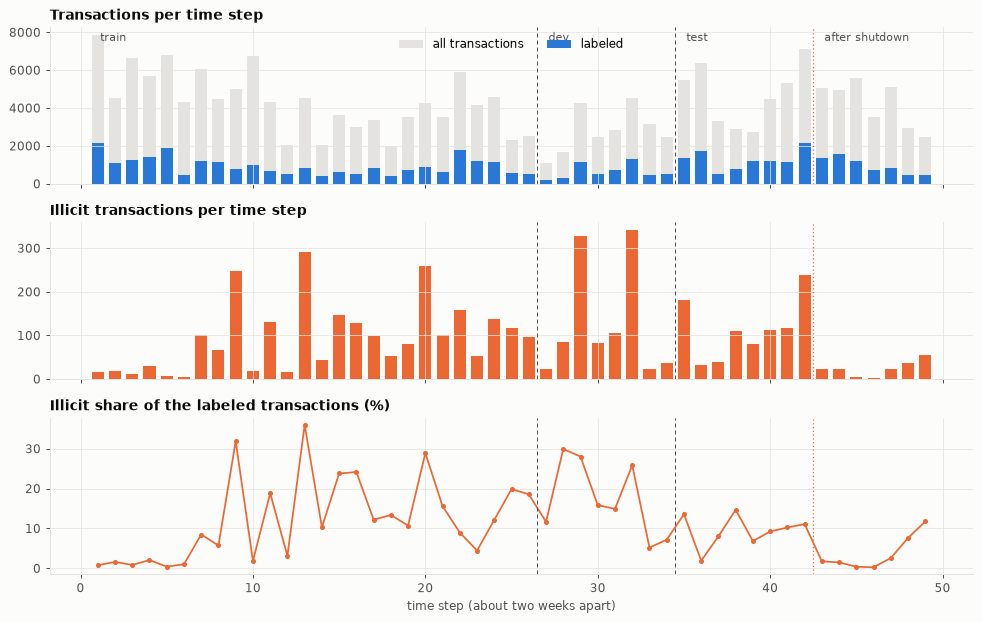

labeled: 46,564 of 203,769 (22.9%); illicit among labeled: 9.8%


,transactions,illicit,licit,labeled,labeled share,illicit share of labeled
min,"1,089.000",2.000,182.000,206.000,0.112,0.003
50%,"4,291.000",80.000,710.000,811.000,0.212,0.102
max,"7,880.000",342.000,"2,130.000","2,154.000",0.429,0.360


In [3]:
by_step = nodes.groupby("time_step").agg(
    transactions=("tx_id", "size"),
    illicit=("label", lambda s: int((s == 1).sum())),
    licit=("label", lambda s: int((s == 0).sum())),
)
by_step["labeled"] = by_step["illicit"] + by_step["licit"]
by_step["labeled share"] = by_step["labeled"] / by_step["transactions"]
by_step["illicit share of labeled"] = by_step["illicit"] / by_step["labeled"]

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].bar(by_step.index, by_step["transactions"], color=GRID, width=0.7, label="all transactions")
axes[0].bar(by_step.index, by_step["labeled"], color=BLUE, width=0.7, label="labeled")
axes[0].set_title("Transactions per time step"); axes[0].legend(ncol=2, loc="upper center")
axes[1].bar(by_step.index, by_step["illicit"], color=ORANGE, width=0.7)
axes[1].set_title("Illicit transactions per time step")
axes[2].plot(by_step.index, 100 * by_step["illicit share of labeled"], color=ORANGE, marker="o", markersize=3)
axes[2].set_title("Illicit share of the labeled transactions (%)"); axes[2].set_xlabel("time step (about two weeks apart)")
for ax in axes:
    mark_periods(ax, labels=ax is axes[0])
fig.tight_layout(); plt.show()

print(f"labeled: {len(known):,} of {len(nodes):,} ({100 * len(known) / len(nodes):.1f}%); illicit among labeled: {100 * known['label'].mean():.1f}%")
by_step.describe().loc[["min", "50%", "max"]]

In [4]:
X = nodes[FEATURES]
summary = X.describe().T
sample_corr = np.array(X.sample(20000, random_state=0).corr().abs())
np.fill_diagonal(sample_corr, 0)
pd.Series({
    "features": len(FEATURES),
    "of which local / aggregated over neighbours": f"{len(LOCAL)} / {len(FEATURES) - len(LOCAL)}",
    "range of feature means": f"{summary['mean'].min():.4f} to {summary['mean'].max():.4f}",
    "range of feature standard deviations": f"{summary['std'].min():.4f} to {summary['std'].max():.4f}",
    "largest absolute value": f"{X.abs().max().max():.0f}",
    "features with |skewness| above 10": int((X.skew().abs() > 10).sum()),
    "constant features": int((summary["std"] == 0).sum()),
    "feature pairs with |correlation| above 0.99": int((np.triu(sample_corr) > 0.99).sum()),
    "features in at least one such pair": int((sample_corr.max(axis=0) > 0.99).sum()),
}, name="value").to_frame()

,value
features,165
of which local / aggregated over neighbours,93 / 72
range of feature means,-0.0000 to 0.0000
range of feature standard deviations,1.0000 to 1.0000
largest absolute value,289
features with |skewness| above 10,69
constant features,0
feature pairs with |correlation| above 0.99,47
features in at least one such pair,71


**Sizes.**

- 203,769 transactions, but **only 46,564 (23%) are labeled**, and only 4,545 are illicit: 9.8% of the
  labeled ones, 2.2% of all.
- Time steps have 1,089 to 7,880 transactions. The number of **illicit** transactions per step ranges from
  2 to 342.
- That is enough to train tabular models with a few hundred parameters or trees. It is little for the
  question this project is about: **after the shutdown at step 43 there are only 169 illicit transactions
  in seven steps**, and steps 45 and 46 have 5 and 2. Any score on that period is noisy.

**Class balance changes constantly.** The illicit share of the labeled transactions moves between 0.3% and
36% from step to step, long before the shutdown. After step 42 it collapses to between 0.3% and 2.6% for
five steps.

**Features.**

- All 165 are anonymized and already **standardized over the whole dataset** (every mean is 0, every
  standard deviation 1).
- They are heavy-tailed: values up to 289 standard deviations, 69 features with extreme skewness.
- They are redundant: 71 features are in a pair correlated above 0.99.

### 2.1 Feature set and labels

| | Choice | Why |
| --- | --- | --- |
| **Features** | The 165 published features: 93 "local" ones describing the transaction and 72 "aggregated" ones describing its direct neighbours | They are all there is: the raw transactions are not published, so no new transaction features can be built. |
| **Not a feature** | The time step | It identifies the period. A model that uses it cannot be applied to a later period. |
| **Additional input** | The payment-flow graph within each time step | For graph models and graph-derived features. |
| **Labels** | Illicit (1) or licit (0), for the 23% of transactions where the entity is known | Given with the data. |
| **Unlabeled transactions** | Not used for supervised training or scoring. Available as graph context and for semi-supervised methods. | Their class is unknown, not "licit". |

## 3. Exploratory analysis and preprocessing

Four properties of the data matter for preprocessing and for how results must be read.

### 3.1 Some features are clocks

How much of each feature's variance is explained by the time step alone?

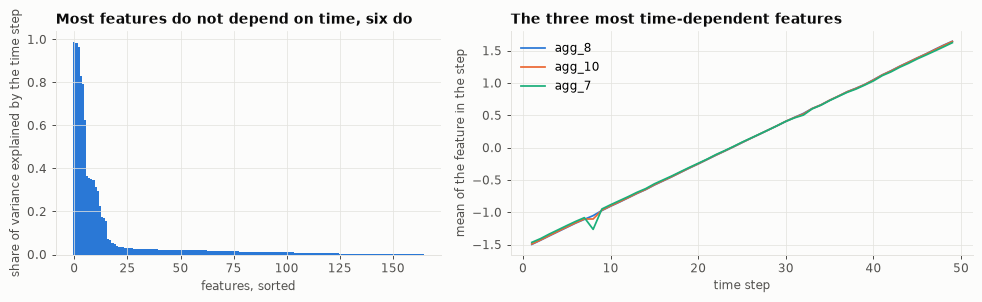

features with more than half of their variance explained by the time step: {'agg_8': np.float64(0.989), 'agg_10': np.float64(0.985), 'agg_7': np.float64(0.967), 'agg_43': np.float64(0.832), 'agg_46': np.float64(0.794), 'agg_44': np.float64(0.627)}
median over all features: 0.013


In [5]:
values, steps = X.to_numpy(), nodes["time_step"].to_numpy()
grand_mean = values.mean(axis=0)
between = np.zeros(values.shape[1])
for step in np.unique(steps):
    rows = steps == step
    between += rows.sum() * (values[rows].mean(axis=0) - grand_mean) ** 2
time_share = pd.Series(between / ((values - grand_mean) ** 2).sum(axis=0), index=FEATURES).sort_values(ascending=False)
CLOCK_FEATURES = list(time_share[time_share > 0.5].index)
NON_CLOCK = [f for f in FEATURES if f not in CLOCK_FEATURES]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].bar(range(len(time_share)), time_share.to_numpy(), color=BLUE, width=1.0)
axes[0].set_xlabel("features, sorted"); axes[0].set_ylabel("share of variance explained by the time step")
axes[0].set_title("Most features do not depend on time, six do")
step_means = nodes.groupby("time_step")[CLOCK_FEATURES[:3]].mean()
for name, color in zip(step_means.columns, [BLUE, ORANGE, AQUA]):
    axes[1].plot(step_means.index, step_means[name], color=color, label=name)
axes[1].set_xlabel("time step"); axes[1].set_ylabel("mean of the feature in the step")
axes[1].set_title("The three most time-dependent features"); axes[1].legend()
fig.tight_layout(); plt.show()
print("features with more than half of their variance explained by the time step:", {f: round(time_share[f], 3) for f in CLOCK_FEATURES})
print(f"median over all features: {time_share.median():.3f}")

**Six aggregated features are essentially clocks.** The time step explains 63 to 99% of their variance,
and their step means rise in a straight line. They most likely encode a block height or timestamp of
neighbouring transactions. Consequences:

- Although the time step was removed from the features, **time is still in them.** A model can tell which
  period a transaction is from.
- A tree model cannot extrapolate along such a feature: test-period values lie beyond everything seen in
  training.
- Section 4 shows that dropping them does not change the baseline's scores, so they are kept there for
  comparability with published results. For drift detection they must be removed (section 5.3).

### 3.2 Illicit transactions come in bursts of near-copies

In [6]:
train_dev = known[known["time_step"] <= DEV_END]
nn = NearestNeighbors(n_neighbors=2).fit(train_dev[FEATURES])
distance, index = nn.kneighbors(train_dev[FEATURES])
nearest_distance, nearest = distance[:, 1], index[:, 1]
labels, steps_td = train_dev["label"].to_numpy(), train_dev["time_step"].to_numpy()

rows = {}
for name, value in [("illicit", 1), ("licit", 0)]:
    mask = labels == value
    rows[name] = {
        "transactions": int(mask.sum()),
        "median distance to the nearest other transaction": np.median(nearest_distance[mask]),
        "share with a neighbour closer than 0.1": (nearest_distance[mask] < 0.1).mean(),
        "nearest neighbour has the same label": (labels[nearest[mask]] == value).mean(),
        "nearest neighbour is in the same time step": (steps_td[nearest[mask]] == steps_td[mask]).mean(),
    }
print("Nearest neighbour among the labeled transactions of steps 1 to 34 (Euclidean distance over 165 standardized features):")
pd.DataFrame(rows)

Nearest neighbour among the labeled transactions of steps 1 to 34 (Euclidean distance over 165 standardized features):


,illicit,licit
transactions,"3,462.000","26,432.000"
median distance to the nearest other transaction,0.304,4.189
share with a neighbour closer than 0.1,0.336,0.020
nearest neighbour has the same label,0.895,0.979
nearest neighbour is in the same time step,0.627,0.376


**Illicit transactions are far more clustered than licit ones.** The median illicit transaction has another
labeled transaction at distance 0.3, where the median licit one has its nearest at 4.2. A third of the
illicit transactions have a near-copy (distance below 0.1), and most of these nearest neighbours are in the
same time step and also illicit. Illicit activity appears as bursts of almost identical transactions,
presumably from the same entity.

Consequences:

- **A random split would leak.** Near-copies of a test transaction would sit in the training set, and a
  model could score highly by memorizing them. Only a split by time is valid.
- **The effective number of illicit examples is much smaller than 4,545.** What a model learns is closer to
  "a few hundred illicit patterns".
- Scores inside a time step are not independent, so confidence intervals from resampling transactions are
  too narrow.

### 3.3 Other preprocessing decisions

| Issue found in the data | Decision |
| --- | --- |
| The time step is a column of the feature file | Removed from the features. |
| Six features act as clocks | Kept in the baseline for comparability (they make no difference there), removed for drift detection. Recommended to drop in new models. |
| Features were standardized over the whole dataset, test period included | Cannot be undone, since the raw values are not published. It is a mild leak of test-period scale into training. Tree models are unaffected by rescaling. |
| Heavy tails | No action for tree models. For linear or neural models a rank or log transform should be tried, fitted on train only. |
| 71 highly correlated features | No action for tree models. Matters for interpreting feature importances. |
| 77% of transactions are unlabeled | Excluded from training and scoring of supervised models. Never treated as licit. |
| Edges | All within a time step, so the graph cannot carry information across the split. |
| Illicit bursts | Split by time only; report scores per time step. |

In [7]:
parts = el.temporal_split(nodes, TRAIN_END, DEV_END)
period = np.select(
    [nodes["time_step"] <= TRAIN_END, nodes["time_step"] <= DEV_END, nodes["time_step"] < SHUTDOWN],
    ["train", "dev", "test before shutdown"], "test after shutdown")
nodes["period"] = period
known = el.labeled(nodes)

split_table = nodes.groupby("period").agg(
    first_step=("time_step", "min"), last_step=("time_step", "max"), transactions=("tx_id", "size"),
    labeled=("label", lambda s: int((s >= 0).sum())), illicit=("label", lambda s: int((s == 1).sum())),
).loc[["train", "dev", "test before shutdown", "test after shutdown"]]
split_table["illicit share of labeled"] = split_table["illicit"] / split_table["labeled"]

# Save the split assignment for later experiments (data/ is ignored by git).
nodes[["tx_id", "time_step", "label", "period"]].assign(
    split=nodes["period"].str.split(" ").str[0]).to_parquet(el.DATA_DIR / "splits.parquet")
split_table

,first_step,last_step,transactions,labeled,illicit,illicit share of labeled
period,,,,,,
train,1,26,113787,24717,2433,0.098
dev,27,34,22478,5177,1029,0.199
test before shutdown,35,42,37820,9983,914,0.092
test after shutdown,43,49,29684,6687,169,0.025


### 3.4 The split

**By time step:** train is steps 1 to 26, dev 27 to 34, test 35 to 49.

- **The test period is the one used by Weber et al. (2019) and most later work** (steps 35 to 49), so
  results are comparable with the literature. Their training period (1 to 34) is divided here into train
  and dev.
- **Dev** is for choosing models and settings. For the final test score, a model may be refitted on train
  and dev together, which is exactly the published protocol.
- **The test period is reported in two parts,** before the shutdown (35 to 42) and after it (43 to 49),
  because they behave completely differently. One average over both hides that.
- The illicit share differs strongly between the parts: 10% in train, 20% in dev, 9% before and 2.5% after
  the shutdown.

**A limitation that no split can fix:** there is one shutdown event, and it lies in the test period. Methods
that adapt to drift can only be tuned on dev, where there is no comparable event.

### 3.5 Leakage checklist

| Risk | How it is handled |
| --- | --- |
| Random split mixes near-copies across train and test | Split by time step only (`el.temporal_split`, tested). |
| Time step used as a feature | Removed. Six clock features remain in the published feature set and are flagged. |
| Graph models see test-period nodes or edges during training | Not applicable to the tabular baseline. For graph models: train on the graph of the training steps only. Recent work shows that getting this wrong changes results by tens of F1 points (see the literature review). |
| Aggregated features use neighbours | The neighbours are in the same time step, and no labels enter the features, so this is not a leak. |
| Standardization over all periods | Present in the published data, cannot be removed. Documented. |
| Threshold or settings tuned on test | Baselines use the default threshold of 0.5 and published settings. Anything that looks at test labels is marked as a diagnostic. |
| Walk-forward retraining uses test labels | Only labels from steps before the one being scored (`el.walk_forward_scores`, tested by changing future labels). Whether labels are really available that quickly is a separate question, examined in section 5.4. |

## 4. Baseline

### 4.1 Task, metrics and protocol

**Task.** Classify each labeled transaction of a later period as illicit or licit, having trained only on
earlier periods.

**Metrics.** All refer to the illicit class, which is the one that matters and the rare one.

| Metric | Definition | Why |
| --- | --- | --- |
| **Illicit F1** (main, with precision and recall) | at the default threshold 0.5 | The standard on this dataset, so results can be compared with the literature. Accuracy would be useless: calling everything licit is 90% accurate. |
| **Average precision** | area under the precision-recall curve | Judges the ranking of transactions without a threshold. On imbalanced data it is more informative than ROC AUC (Saito and Rehmsmeier, 2015). It separates "the model ranks badly" from "the threshold is in the wrong place", which turns out to be essential here. |
| **Per time step and per period** | the same metrics for each step, and before / after the shutdown | The project is about change over time. A single number over steps 35 to 49 averages two different regimes. |
| **Bootstrap intervals** | resampling transactions | To show how little the post-shutdown period can tell with 169 illicit transactions. Because of the bursts they are optimistic. |

**Protocol.**

1. Fit on train (steps 1 to 26), score dev (27 to 34).
2. Refit on train and dev (1 to 34), score test (35 to 49) once. This is the protocol of Weber et al.
3. No refitting during the test period, threshold 0.5.

**Baselines.**

| Model | Settings |
| --- | --- |
| Flag everything | The trivial reference for F1. |
| Logistic regression | scikit-learn defaults, as in Weber et al. |
| **Random forest (the fixed baseline)** | 50 trees, 50 features tried per split, as in Weber et al. All 165 features. |
| Random forest on local features | The same on the 93 local features, to see what the neighbour aggregates add. |
| Random forest without the clock features | The same without the six features of section 3.1. |

In [8]:
def random_forest(n_features=len(FEATURES), seed=0):
    return RandomForestClassifier(n_estimators=50, max_features=min(50, n_features), n_jobs=-1, random_state=seed)

def logistic():
    return LogisticRegression(max_iter=1000)

train = known[known["period"] == "train"]
dev = known[known["period"] == "dev"]
train_dev = known[known["time_step"] <= DEV_END]
test = known[known["time_step"] > DEV_END]
before, after = (test["time_step"] < SHUTDOWN).to_numpy(), (test["time_step"] >= SHUTDOWN).to_numpy()

def evaluate(y, scores):
    result = el.illicit_scores(y, scores)
    return {"precision": result["precision"], "recall": result["recall"], "F1": result["f1"],
            "average precision": el.ranking_scores(y, scores)["average_precision"]}

MODELS = {
    "Logistic regression": (logistic, FEATURES),
    "Random forest (fixed baseline)": (lambda: random_forest(), FEATURES),
    "Random forest, local features": (lambda: random_forest(len(LOCAL)), LOCAL),
    "Random forest, no clock features": (lambda: random_forest(len(NON_CLOCK)), NON_CLOCK),
}
rows, test_scores = {}, {}
for name, (make, features) in MODELS.items():
    dev_scores = make().fit(train[features], train["label"]).predict_proba(dev[features])[:, 1]
    scores = make().fit(train_dev[features], train_dev["label"]).predict_proba(test[features])[:, 1]
    test_scores[name] = scores
    row = {("dev (27-34)", k): v for k, v in evaluate(dev["label"], dev_scores).items()}
    row.update({("test (35-49)", k): v for k, v in evaluate(test["label"], scores).items()})
    row[("test before shutdown", "F1")] = evaluate(test["label"][before], scores[before])["F1"]
    row[("test after shutdown", "F1")] = evaluate(test["label"][after], scores[after])["F1"]
    rows[name] = row
share = {"dev (27-34)": dev["label"].mean(), "test (35-49)": test["label"].mean()}
rows = {"Flag everything": {(k, "precision"): p for k, p in share.items()} | {(k, "recall"): 1.0 for k in share}
        | {(k, "F1"): 2 * p / (1 + p) for k, p in share.items()} | {(k, "average precision"): p for k, p in share.items()}} | rows
baseline_table = pd.DataFrame(rows).T
baseline_table.columns = pd.MultiIndex.from_tuples(baseline_table.columns)
baseline_table

,dev (27-34),test (35-49),dev (27-34),test (35-49),dev (27-34),test (35-49),dev (27-34),test (35-49),test before shutdown,test after shutdown
,precision,precision,recall,recall,F1,F1,average precision,average precision,F1,F1
Flag everything,0.199,0.065,1.000,1.000,0.332,0.122,0.199,0.065,NaN,NaN
Logistic regression,0.622,0.322,0.925,0.698,0.744,0.440,0.723,0.335,0.573,0.048
Random forest (fixed baseline),0.988,0.900,0.936,0.724,0.961,0.802,0.980,0.785,0.899,0.028
"Random forest, local features",0.981,0.844,0.895,0.712,0.936,0.772,0.967,0.771,0.872,0.026
"Random forest, no clock features",0.988,0.928,0.932,0.717,0.959,0.809,0.986,0.779,0.905,0.028


In [9]:
# Reproduction check against Weber et al. (2019), and stability over random seeds.
BASE = "Random forest (fixed baseline)"
published = pd.DataFrame({
    "Logistic regression": {"precision": 0.404, "recall": 0.593, "F1": 0.481},
    "Random forest (fixed baseline)": {"precision": 0.956, "recall": 0.670, "F1": 0.788},
    "Random forest, local features": {"precision": 0.803, "recall": 0.611, "F1": 0.694},
}).T
ours = baseline_table["test (35-49)"].loc[published.index, ["precision", "recall", "F1"]]
display(pd.concat({"this notebook": ours, "Weber et al. (2019)": published}, axis=1))

seed_f1 = [el.illicit_scores(test["label"], random_forest(seed=s).fit(train_dev[FEATURES], train_dev["label"]).predict_proba(test[FEATURES])[:, 1])["f1"] for s in range(1, 6)]
f1 = lambda y, s: el.illicit_scores(y, s)["f1"]
low, high = el.bootstrap_interval(test["label"], test_scores[BASE], f1, n_boot=1000)
print(f"random forest test F1 over five other seeds: {np.round(seed_f1, 3).tolist()}")
print(f"bootstrap 95% interval of the test F1 (seed 0): {low:.3f} to {high:.3f}")

this notebook              Weber et al. (2019)             
                                   precision recall    F1           precision recall    F1
Logistic regression                    0.322  0.698 0.440               0.404  0.593 0.481
Random forest (fixed baseline)         0.900  0.724 0.802               0.956  0.670 0.788
Random forest, local features          0.844  0.712 0.772               0.803  0.611 0.694

random forest test F1 over five other seeds: [0.812, 0.808, 0.811, 0.811, 0.805]
bootstrap 95% interval of the test F1 (seed 0): 0.783 to 0.821


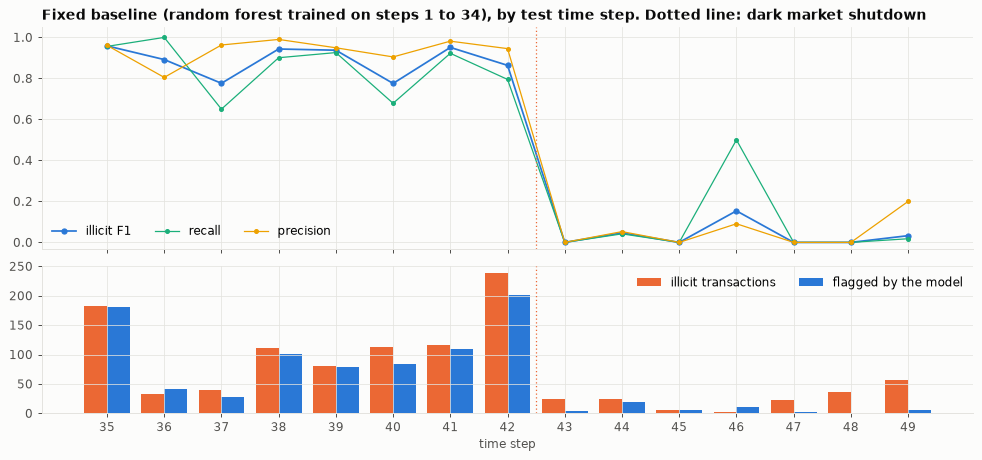

time_step,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49
precision,0.961,0.805,0.963,0.990,0.949,0.905,0.982,0.945,0.000,0.053,0.000,0.091,0.000,0.000,0.200
recall,0.956,1.000,0.650,0.901,0.926,0.679,0.922,0.795,0.000,0.042,0.000,0.500,0.000,0.000,0.018
f1,0.959,0.892,0.776,0.943,0.938,0.776,0.951,0.864,0.000,0.047,0.000,0.154,0.000,0.000,0.033
n_illicit,182.000,33.000,40.000,111.000,81.000,112.000,116.000,239.000,24.000,24.000,5.000,2.000,22.000,36.000,56.000
n_flagged,181.000,41.000,27.000,101.000,79.000,84.000,109.000,201.000,4.000,19.000,6.000,11.000,3.000,0.000,5.000
illicit_share,0.136,0.019,0.080,0.147,0.068,0.092,0.102,0.111,0.018,0.015,0.004,0.003,0.026,0.076,0.118


In [10]:
static_steps = el.per_step_scores(test["time_step"], test["label"], test_scores[BASE])
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
axes[0].plot(static_steps.index, static_steps["f1"], color=BLUE, marker="o", markersize=4, label="illicit F1")
axes[0].plot(static_steps.index, static_steps["recall"], color=AQUA, marker="o", markersize=3, linewidth=1.0, label="recall")
axes[0].plot(static_steps.index, static_steps["precision"], color=YELLOW, marker="o", markersize=3, linewidth=1.0, label="precision")
axes[0].axvline(SHUTDOWN - 0.5, color=ORANGE, linewidth=1.0, linestyle=(0, (1, 2)))
axes[0].set_ylim(-0.03, 1.05); axes[0].set_title("Fixed baseline (random forest trained on steps 1 to 34), by test time step. Dotted line: dark market shutdown")
axes[0].legend(ncol=3, loc="lower left")
axes[1].bar(static_steps.index - 0.2, static_steps["n_illicit"], width=0.4, color=ORANGE, label="illicit transactions")
axes[1].bar(static_steps.index + 0.2, static_steps["n_flagged"], width=0.4, color=BLUE, label="flagged by the model")
axes[1].axvline(SHUTDOWN - 0.5, color=ORANGE, linewidth=1.0, linestyle=(0, (1, 2)))
axes[1].set_xlabel("time step"); axes[1].set_xticks(static_steps.index); axes[1].legend(ncol=2)
fig.tight_layout(); plt.show()
static_steps[["precision", "recall", "f1", "n_illicit", "n_flagged", "illicit_share"]].T

### 4.2 How the baseline performs

- **The published results are reproduced, approximately.** The random forest reaches an illicit F1 of 0.80
  on the test period (0.79 in the paper, 0.80 to 0.81 over other seeds), logistic regression 0.44 (0.48 in
  the paper). The largest gap is for the random forest on local features: 0.77 here against 0.69 published.
  The paper does not give a seed or the library version, and it may have counted the time step among the
  local features, which is excluded here.
- **The random forest is a strong baseline.** On dev it reaches F1 0.96, and on the test steps before the
  shutdown 0.90, with precision around 0.95. Logistic regression is far behind (0.74 on dev).
- **After the shutdown it finds nothing.** F1 is 0.03: of 169 illicit transactions it catches 3. The test
  F1 of 0.80 is the average of two regimes, 0.90 and 0.03, weighted by how many illicit transactions each
  has. Reported alone, it says little about either.
- **Dev is easier than test,** even before the shutdown (0.96 against 0.90). Performance already declines
  with distance from the training period.
- **The neighbour aggregates help a little** (0.80 against 0.77 without them), and **the clock features
  make no difference.**
- **The headline number is statistically solid, the post-shutdown number is not:** the bootstrap interval
  of the test F1 is about 0.78 to 0.82, while single post-shutdown steps have between 2 and 56 illicit
  transactions.

## 5. Method fit: what is the drift, can it be detected, can it be adapted to?

The idea proposes to (1) separate covariate shift from concept shift, (2) detect the drift without labels,
and (3) adapt by retraining. Each is checked here in its simplest form.

### 5.1 What changes at the shutdown

In [11]:
def rates(frame, scores):
    y = frame["label"].to_numpy()
    flagged = scores >= 0.5
    return {
        "labeled": len(y), "illicit": int(y.sum()), "illicit share": y.mean(),
        "recall (share of illicit flagged)": flagged[y == 1].mean(),
        "false positive rate (share of licit flagged)": flagged[y == 0].mean(),
        "mean score of illicit": scores[y == 1].mean(), "mean score of licit": scores[y == 0].mean(),
        "average precision": el.ranking_scores(y, scores)["average_precision"],
        "ROC AUC": el.ranking_scores(y, scores)["roc_auc"],
    }

static = test_scores[BASE]
pd.DataFrame({"test before shutdown (35-42)": rates(test[before], static[before]),
              "test after shutdown (43-49)": rates(test[after], static[after])})

,test before shutdown (35-42),test after shutdown (43-49)
labeled,"9,983.000","6,687.000"
illicit,914.000,169.000
illicit share,0.092,0.025
recall (share of illicit flagged),0.854,0.018
false positive rate (share of licit flagged),0.005,0.007
mean score of illicit,0.825,0.091
mean score of licit,0.054,0.074
average precision,0.911,0.044
ROC AUC,0.968,0.618


,dev (27-34),test before shutdown (35-42),test after shutdown (43-49)
illicit transactions,"1,029.000",914.000,169.000
median distance to nearest earlier illicit,1.442,1.323,8.680
median distance to nearest earlier licit,2.112,1.791,7.218
share closer to an earlier illicit than to an earlier licit,0.861,0.777,0.089
share within distance 1 of an earlier illicit,0.360,0.342,0.000


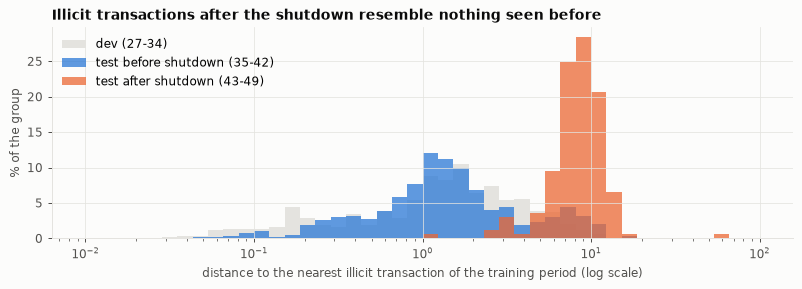

In [12]:
# How close is each illicit transaction to the illicit and licit transactions of earlier periods?
def distance_to_past(queries, past):
    to_illicit = NearestNeighbors(n_neighbors=1).fit(past[past["label"] == 1][NON_CLOCK]).kneighbors(queries[NON_CLOCK])[0][:, 0]
    to_licit = NearestNeighbors(n_neighbors=1).fit(past[past["label"] == 0][NON_CLOCK]).kneighbors(queries[NON_CLOCK])[0][:, 0]
    return to_illicit, to_licit

groups = {
    "dev (27-34)": (dev[dev["label"] == 1], train),
    "test before shutdown (35-42)": (test[before & (test["label"] == 1).to_numpy()], train_dev),
    "test after shutdown (43-49)": (test[after & (test["label"] == 1).to_numpy()], train_dev),
}
rows, distances = {}, {}
for name, (queries, past) in groups.items():
    to_illicit, to_licit = distance_to_past(queries, past)
    distances[name] = to_illicit
    rows[name] = {"illicit transactions": len(queries),
                  "median distance to nearest earlier illicit": np.median(to_illicit),
                  "median distance to nearest earlier licit": np.median(to_licit),
                  "share closer to an earlier illicit than to an earlier licit": (to_illicit < to_licit).mean(),
                  "share within distance 1 of an earlier illicit": (to_illicit < 1).mean()}
display(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(9, 3.3))
bins = np.logspace(-2, 2, 45)
for (name, values), color in zip(distances.items(), [GRID, BLUE, ORANGE]):
    ax.hist(np.clip(values, 0.011, 99), bins=bins, color=color, alpha=0.75 if color != GRID else 1.0, label=name, weights=np.full(len(values), 100 / len(values)))
ax.set_xscale("log"); ax.set_xlabel("distance to the nearest illicit transaction of the training period (log scale)"); ax.set_ylabel("% of the group")
ax.set_title("Illicit transactions after the shutdown resemble nothing seen before"); ax.legend()
fig.tight_layout(); plt.show()

**The drift is the arrival of a new kind of illicit transaction, together with the disappearance of the old
kind.**

- **The licit side is unchanged.** The false positive rate is about 0.5% before and 0.7% after.
- **The illicit side is replaced.** Recall falls from 85% to 2%. The model's mean score for an illicit
  transaction falls from 0.83 to 0.09: after the shutdown the model is confident that illicit transactions
  are licit. Its ranking is barely better than random (ROC AUC 0.62).
- **The illicit share falls** from 9% to 2.5%, so there is also a shift in class balance. But a shift in
  balance alone would leave recall intact. It does not explain the collapse.
- **The new illicit transactions are far from all earlier ones.** Before the shutdown, the typical illicit
  transaction lies at distance 1.3 from an illicit transaction of the training period, a third lie within
  distance 1, and about 80% are closer to an earlier illicit than to an earlier licit one. After the
  shutdown the typical distance is 8.7, none lies within distance 1, and only 9% are closer to an earlier
  illicit transaction than to a licit one.

In the usual vocabulary this is neither pure covariate shift nor a change of the labeling rule for existing
inputs. It is a **change of the class-conditional distribution**: illicit transactions move to a region of
feature space where the training data had only licit ones. Together with section 3.2, the picture is that
the classifier had learned to recognize the transaction patterns of particular illicit entities, and those
entities stopped operating.

### 5.2 Can the drift be detected without labels?

The standard tool is a classifier two-sample test: train a classifier to tell old data from new data. If it
cannot (AUC near 0.5), nothing has shifted.

In [13]:
def domain(a, b, features, n=3000):
    a = a.sample(min(n, len(a)), random_state=0)
    b = b.sample(min(n, len(b)), random_state=0)
    return el.domain_auc(a[features], b[features], n_estimators=50)

shuffled = nodes[nodes["time_step"] <= TRAIN_END].sample(frac=1, random_state=1)
train_all = nodes[nodes["time_step"] <= TRAIN_END]
comparisons = {
    "two random halves of train (no shift)": (shuffled.iloc[: len(shuffled) // 2], shuffled.iloc[len(shuffled) // 2:]),
    "step 20 against step 21": (nodes[nodes["time_step"] == 20], nodes[nodes["time_step"] == 21]),
    "step 41 against step 42 (before the shutdown)": (nodes[nodes["time_step"] == 41], nodes[nodes["time_step"] == 42]),
    "step 42 against step 43 (across the shutdown)": (nodes[nodes["time_step"] == 42], nodes[nodes["time_step"] == 43]),
    "train against dev": (train_all, nodes[nodes["period"] == "dev"]),
    "train against test before shutdown": (train_all, nodes[nodes["period"] == "test before shutdown"]),
    "train against test after shutdown": (train_all, nodes[nodes["period"] == "test after shutdown"]),
}
start = time.time()
detection = pd.DataFrame({name: {"all 165 features": domain(a, b, FEATURES), "without the 6 clock features": domain(a, b, NON_CLOCK),
                                 "local features only": domain(a, b, LOCAL)} for name, (a, b) in comparisons.items()}).T
print(f"ROC AUC of telling the two samples apart (0.5 = indistinguishable), all transactions, labels not used   ({time.time() - start:.0f}s)")
detection

ROC AUC of telling the two samples apart (0.5 = indistinguishable), all transactions, labels not used   (15s)


,all 165 features,without the 6 clock features,local features only
two random halves of train (no shift),0.502,0.493,0.504
step 20 against step 21,1.000,0.925,0.910
step 41 against step 42 (before the shutdown),1.000,0.955,0.945
step 42 against step 43 (across the shutdown),1.000,0.961,0.940
train against dev,1.000,0.958,0.941
train against test before shutdown,1.000,0.994,0.984
train against test after shutdown,1.000,0.988,0.975


**Not with this tool.** A classifier separates any two periods perfectly, including two neighbouring time
steps in the middle of the training period. Removing the clock features lowers that only to about 0.9.
Every time step is a different sample of the Bitcoin network, so "the distribution has shifted" is true
always, and step 43 does not stand out from step 21 or 42.

The drift that hurts is confined to the illicit class, about 2% of the transactions, and is invisible in
the feature distribution as a whole. Detecting it will need something more specific: monitoring the model's
own outputs (the number of transactions it flags drops sharply after step 42, see the chart in section 4),
or tests calibrated against the normal step-to-step variation.

### 5.3 Does retraining help?

The simplest adaptation: before scoring each test step, retrain the same random forest on all labeled
transactions of earlier steps. This assumes that the labels of a step are known before the next step
begins, about two weeks later. Two variants: a sliding window of the last 5 steps, and labels that arrive
two steps (about a month) late.

These runs use test-period labels, but only from steps before the one being scored. Nothing is tuned.

In [14]:
start = time.time()
variants = {
    "Static (trained on steps 1-34)": pd.Series(static, index=test.index),
    "Retrained every step, all history": el.walk_forward_scores(nodes, FEATURES, random_forest, DEV_END + 1, 49),
    "Retrained every step, last 5 steps": el.walk_forward_scores(nodes, FEATURES, random_forest, DEV_END + 1, 49, window=5),
    "Retrained every step, labels 2 steps late": el.walk_forward_scores(nodes, FEATURES, random_forest, DEV_END + 1, 49, label_delay=2),
}
print(f"walk-forward runs: {time.time() - start:.0f}s")

ap = lambda y, s: el.ranking_scores(y, s)["average_precision"]
y_after = test["label"][after]
rows = {}
for name, scores in variants.items():
    scores = scores.loc[test.index].to_numpy()
    row = {}
    for label, mask in [("before shutdown", before), ("after shutdown", after)]:
        result = evaluate(test["label"][mask], scores[mask])
        for key in ["precision", "recall", "F1", "average precision"]:
            row[(label, key)] = result[key]
    f1_low, f1_high = el.bootstrap_interval(y_after, scores[after], f1, n_boot=500)
    ap_low, ap_high = el.bootstrap_interval(y_after, scores[after], ap, n_boot=500)
    row[("after shutdown", "F1 95% interval")] = f"{f1_low:.2f} to {f1_high:.2f}"
    row[("after shutdown", "AP 95% interval")] = f"{ap_low:.2f} to {ap_high:.2f}"
    best = el.best_f1_threshold(y_after, scores[after])     # diagnostic: uses the labels being scored
    row[("diagnostic", "best possible F1 after shutdown")] = el.illicit_scores(y_after, scores[after], best)["f1"]
    row[("diagnostic", "at threshold")] = best
    rows[name] = row
adaptation = pd.DataFrame(rows).T
adaptation.columns = pd.MultiIndex.from_tuples(adaptation.columns)
adaptation

walk-forward runs: 172s


before shutdown                                after shutdown                                                                                     diagnostic             
                                                precision recall    F1 average precision      precision recall    F1 average precision F1 95% interval AP 95% interval best possible F1 after shutdown at threshold
Static (trained on steps 1-34)                      0.949  0.854 0.899             0.911          0.062  0.018 0.028             0.044    0.00 to 0.06    0.03 to 0.07                           0.071        0.040
Retrained every step, all history                   0.982  0.847 0.910             0.921          0.821  0.136 0.234             0.514    0.15 to 0.32    0.43 to 0.60                           0.553        0.320
Retrained every step, last 5 steps                  0.979  0.825 0.895             0.902          0.805  0.195 0.314             0.395    0.23 to 0.39    0.32 to 0.48                           0.480        0.380
Retrained every step, labels 2 steps late           0.965  0.847 0.902             0.909          0.333  0.018 0.034             0.101    0.00 to 0.07    0.08 to 0.14                           0.177        0.180

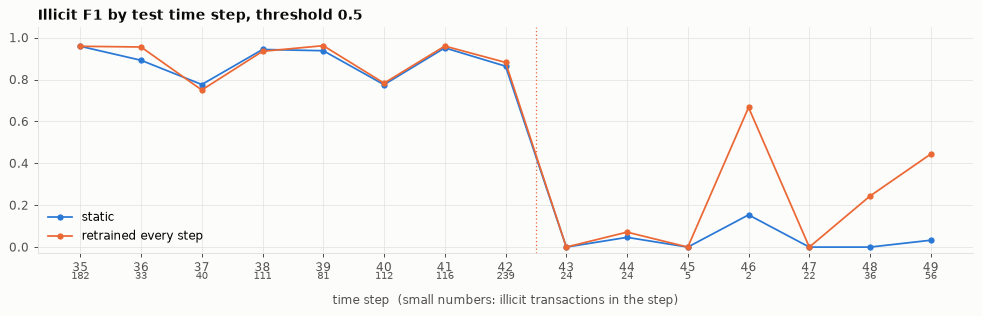

Upper bound for steps 43 to 49 (model has seen every other step, also later ones): {'precision': 0.846, 'recall': 0.13, 'F1': 0.226, 'average precision': 0.563, 'ROC AUC': 0.953}


In [15]:
retrained = variants["Retrained every step, all history"].loc[test.index].to_numpy()
retrained_steps = el.per_step_scores(test["time_step"], test["label"], retrained)

# Diagnostic upper bound: each post-shutdown step scored by a model that saw all other steps, later ones included.
oracle = []
for step in range(SHUTDOWN, 50):
    rest, current = known[known["time_step"] != step], known[known["time_step"] == step]
    oracle.append(pd.Series(random_forest().fit(rest[FEATURES], rest["label"]).predict_proba(current[FEATURES])[:, 1], index=current.index))
oracle = pd.concat(oracle)
oracle_result = {**evaluate(known.loc[oracle.index, "label"], oracle.to_numpy()), "ROC AUC": el.ranking_scores(known.loc[oracle.index, "label"], oracle.to_numpy())["roc_auc"]}

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(static_steps.index, static_steps["f1"], color=BLUE, marker="o", markersize=4, label="static")
ax.plot(retrained_steps.index, retrained_steps["f1"], color=ORANGE, marker="o", markersize=4, label="retrained every step")
ax.axvline(SHUTDOWN - 0.5, color=ORANGE, linewidth=1.0, linestyle=(0, (1, 2)))
for step, n in static_steps["n_illicit"].items():
    ax.annotate(f"{int(n)}", (step, -0.02), ha="center", va="top", fontsize=8, color=MUTED, annotation_clip=False, xytext=(0, -16), textcoords="offset points")
ax.set_ylim(-0.03, 1.05); ax.set_xticks(static_steps.index); ax.set_xlabel("time step  (small numbers: illicit transactions in the step)", labelpad=16)
ax.set_title("Illicit F1 by test time step, threshold 0.5"); ax.legend(loc="lower left")
fig.tight_layout(); plt.show()
print("Upper bound for steps 43 to 49 (model has seen every other step, also later ones):", {k: round(v, 3) for k, v in oracle_result.items()})

**Retraining recovers the ranking but not the decisions.**

- **Before the shutdown, retraining adds little** (F1 0.91 against 0.90). The static model was already
  good.
- **After the shutdown, the ranking improves enormously:** average precision rises from 0.04 to 0.51, and
  the bootstrap intervals do not come near each other. A model that has seen a few dozen examples of the
  new kind puts them near the top.
- **But the F1 at the default threshold stays low** (0.23, recall 14%). The new illicit transactions get
  scores between the licit ones and 0.5: above everything else, below the line. With the best threshold in
  hindsight the same scores would give an F1 of about 0.55. The model knows more than its decisions show.
  This is the main opening for a better method: adapting the threshold or the calibration, or giving recent
  examples more weight.
- **This refines a statement in the original paper,** that a random forest retrained after every step is
  "not able to reliably capture new illicit transactions". That is true of its decisions at threshold 0.5,
  and not true of its ranking.
- **Timely labels are the condition for all of it.** If labels arrive two steps late, the gain is almost
  gone (average precision 0.10). In practice, labels for illicit activity take months or years, since they
  come from investigations. Any claim about adaptation depends on an assumption about label delay, which
  has to be stated.
- **A shorter memory is not clearly better:** the 5-step window has a higher F1 after the shutdown (0.31)
  but a lower average precision (0.40) than the full history, and the intervals overlap.
- **Even the upper bound is modest.** A model that has seen every other step, later ones included, reaches
  an average precision of 0.56 on the post-shutdown steps. With 169 examples spread over seven steps, the
  new pattern stays hard to learn.

### 5.4 What about the graph?

The idea proposes a graph neural network as part of the model comparison. No graph model is trained here.
Two reasons it was not the priority:

In [16]:
edge_table = el.edge_label_table(edges, nodes)
display(edge_table)
labeled_edges = edge_table.loc[["illicit", "licit"], ["illicit", "licit"]]
from_illicit = edge_table.loc["illicit"] + edge_table["illicit"]
print(f"edges with both ends labeled: {int(labeled_edges.to_numpy().sum()):,} of {len(edges):,}")
print(f"of the labeled neighbours of illicit transactions, {100 * 2 * edge_table.loc['illicit', 'illicit'] / (2 * edge_table.loc['illicit', 'illicit'] + edge_table.loc['illicit', 'licit'] + edge_table.loc['licit', 'illicit']):.0f}% are illicit (base rate {100 * known['label'].mean():.0f}%)")
print(f"of all neighbours of illicit transactions, {100 * (edge_table.loc['illicit', 'unknown'] + edge_table.loc['unknown', 'illicit']) / from_illicit.sum():.0f}% are unlabeled")
degree = pd.concat([edges["src"], edges["dst"]]).value_counts()
print(f"edges per transaction: median {degree.median():.0f}, mean {2 * len(edges) / len(nodes):.1f}")

destination,illicit,licit,unknown
source,,,
illicit,998,915,1458
licit,781,33930,15116
unknown,3993,45386,131778


edges with both ends labeled: 36,624 of 234,355
of the labeled neighbours of illicit transactions, 54% are illicit (base rate 10%)
of all neighbours of illicit transactions, 60% are unlabeled
edges per transaction: median 2, mean 2.3


- **The graph does carry signal, but a thin one.** Illicit transactions are connected to other illicit
  transactions far more often than chance. But the graph is sparse (about two edges per transaction), most
  neighbours of an illicit transaction are unlabeled, and the 72 aggregated features already summarize the
  direct neighbours.
- **The literature has settled the comparison for now.** In the original paper the random forest (0.79)
  beat the graph convolutional network (0.63 to 0.71). Two recent re-evaluations under a strictly temporal,
  leakage-free protocol find the same: tree ensembles on the raw features beat every graph network tested
  (see the literature review).

A graph model is therefore a possible extension, not the place where this project is likely to find
something. Its most plausible use is the one suggested by section 5.1: features that describe how close a
transaction is to *known* illicit ones in the graph, which the literature reports to help most after the
shutdown.

## 6. Summary

| Question | Answer |
| --- | --- |
| Is the data usable? | Yes. It matches the published description exactly and is internally consistent. |
| Is there enough? | For the classification task, yes: 46,564 labeled transactions, 4,545 illicit. For studying the drift, barely: one event, 169 illicit transactions after it. |
| Features and labels? | 165 anonymized features (93 local, 72 neighbour aggregates), the graph, and licit / illicit labels for 23% of transactions. The time step is excluded. |
| Preprocessing? | Split by time only; unlabeled transactions excluded; six clock features flagged; no scaling needed for trees. Standardization over the whole dataset is a leak that cannot be undone. |
| Split? | Train steps 1-26, dev 27-34, test 35-49 (the standard test period), reported separately before and after step 43. |
| Baseline? | Random forest: illicit F1 0.96 on dev, 0.80 on test (0.79 published), made of 0.90 before the shutdown and 0.03 after it. |
| What is the drift? | A new kind of illicit transaction, unlike any earlier one, replaces the old kind. The licit class does not change. |
| Can it be detected without labels? | Not by a two-sample test on the features: every time step differs from every other. |
| Does retraining help? | It restores the ranking (average precision 0.04 to 0.51) but not the decisions at a fixed threshold (F1 0.23), and only if labels arrive within one step. |

The full discussion is in [`research/illicit_drift_writeup.md`](../../research/illicit_drift_writeup.md).